# 01 — Données et indice

**Objectif.** Construire l'indice paramétrique de gel $Z$ qui déclenche le contrat, et rassembler les rendements viticoles
qui serviront à juger le risque de base (notebook 03).

**Sources.**
- **Températures** : Météo-France (meteo.data.gouv.fr), données quotidiennes du département de l'Yonne (89), fichiers
  `Q_89_previous-1950-2024_RR-T-Vent.csv.gz` et `Q_89_latest-2025-2026_RR-T-Vent.csv.gz`.
- **Rendements** : douanes (DGDDI), déclarations de récolte, extraites par `scripts/extraire_douanes.py`.

**Plan.** 1. Station et variable de température · 2. Fenêtre de risque et contrôles de qualité ·
3. Indice $Z$ · 4. Rendements viticoles.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"

CHABLIS = 89068001          # station Météo-France CHABLIS_SAPC
FICHIERS = [RAW / "Q_89_previous-1950-2024_RR-T-Vent.csv.gz",
            RAW / "Q_89_latest-2025-2026_RR-T-Vent.csv.gz"]

## 1. Station et variable de température

On utilise les données relevées par la station de Chablis (89068001) Variables candidates pour mesurer le gel :
- **TN** : température minimale sous abri ;
- **TN50** et **TNSOL** : minimales à 50 cm et à 10 cm du sol, plus proches des bourgeons ;
- **DG** : durée de gel.

On retient celle qui a l'historique le plus long et le plus complet.

In [2]:
COLS = ["NUM_POSTE", "AAAAMMJJ", "TN", "QTN", "TN50", "QTN50", "TNSOL", "QTNSOL", "DG", "QDG"]

df = pd.concat([pd.read_csv(f, sep=";", usecols=COLS) for f in FICHIERS], ignore_index=True)
print("Stations dans l'Yonne :", df["NUM_POSTE"].nunique())

meteo = df[df["NUM_POSTE"] == CHABLIS].drop_duplicates().copy()
assert meteo["AAAAMMJJ"].is_unique, "plusieurs lignes pour une même date"

meteo["date"] = pd.to_datetime(meteo["AAAAMMJJ"], format="%Y%m%d")
meteo["annee"] = meteo["date"].dt.year
meteo["mmjj"] = meteo["AAAAMMJJ"] % 10000          # 20210407 -> 407

print(f"Chablis : {len(meteo)} jours, {meteo['annee'].min()}–{meteo['annee'].max()}")
print("Valeurs renseignées :", meteo[["TN", "TN50", "TNSOL", "DG"]].count().to_dict())

Stations dans l'Yonne : 88
Chablis : 27310 jours, 1951–2026
Valeurs renseignées : {'TN': 23354, 'TN50': 0, 'TNSOL': 5598, 'DG': 12994}


## 2. Fenêtre de risque et contrôles de qualité

**Fenêtre : 1er avril – 15 mai.** Fenêtre réaliste pour contenir la date de débourrement des vignes, à partir de laquelle elles sont vulnérables au gel. Une fenêtre fixe garde l'indice simple et vérifiable par le client.

**Contrôles**, sur cette fenêtre de 45 jours : années complètes, part de valeurs renseignées par variable,
codes qualité, valeurs aberrantes.

In [3]:
JOURS_ATTENDUS = 45   # 30 jours d'avril + 15 jours de mai
fenetre = meteo[meteo["mmjj"].between(401, 515)].copy()

# Jours présents dans le fichier et années absentes
jours_presents = fenetre.groupby("annee").size()
toutes_les_annees = range(fenetre["annee"].min(), fenetre["annee"].max() + 1)
print("Années incomplètes :", int((jours_presents < JOURS_ATTENDUS).sum()))
print("Années absentes :", len([a for a in toutes_les_annees if a not in jours_presents.index]))

# Part de valeurs renseignées par année ; une année est utilisable à 90 % ou plus
taux_par_annee = fenetre.groupby("annee")[["TN", "TN50", "TNSOL", "DG"]].count() / JOURS_ATTENDUS
ok = taux_par_annee >= 0.9
print("Années utilisables :", ok.sum().to_dict())
print("Première année utilisable pour TN :", ok.index[ok["TN"]].min())

Années incomplètes : 0
Années absentes : 0
Années utilisables : {'TN': 64, 'TN50': 0, 'TNSOL': 16, 'DG': 34}
Première année utilisable pour TN : 1963


TN est la seule variable couvrant toute la période récente : TN50 n'est jamais mesuré à Chablis,
TNSOL et DG ont des historiques courts. **On retient TN à partir de 1963**, première année complète
(64 années, 1963–2026). Les autres stations et mesures sont examinées dans `04_annexe_stations.ipynb`.

In [4]:
periode_tarification = fenetre[fenetre["annee"] >= 1963]

# Codes qualité de TN (1 = validée)
print(periode_tarification["QTN"].value_counts(dropna=False))

# Valeurs extrêmes : on vérifie la plus haute en regardant les jours voisins
print("TN min / max :", periode_tarification["TN"].min(), periode_tarification["TN"].max())
jour_max = periode_tarification.loc[periode_tarification["TN"].idxmax(), "date"]
voisins = periode_tarification["date"].between(jour_max - pd.Timedelta(days=3), jour_max + pd.Timedelta(days=3))
print(periode_tarification.loc[voisins, ["date", "TN"]].to_string(index=False))

QTN
1.0    2880
Name: count, dtype: int64
TN min / max : -6.0 15.3
      date   TN
1988-05-05  5.7
1988-05-06  5.0
1988-05-07 12.2
1988-05-08 15.3
1988-05-09 14.0
1988-05-10 12.0
1988-05-11 10.6


## 3. Indice $Z$

$$Z_t = \min_{\text{1er avril} \le j \le \text{15 mai}} TN_{t,j}$$

Le contrat paie si $Z$ passe sous le seuil de déclenchement $z_1$ (seuil d'entrée, cf. notebook 02).

**Stationnarité.** La tarification suppose que les 64 années sont tirées de la même loi.
Hypothèse à tester par une GEV à paramètre de position dépendant du temps (piste d'amélioration).

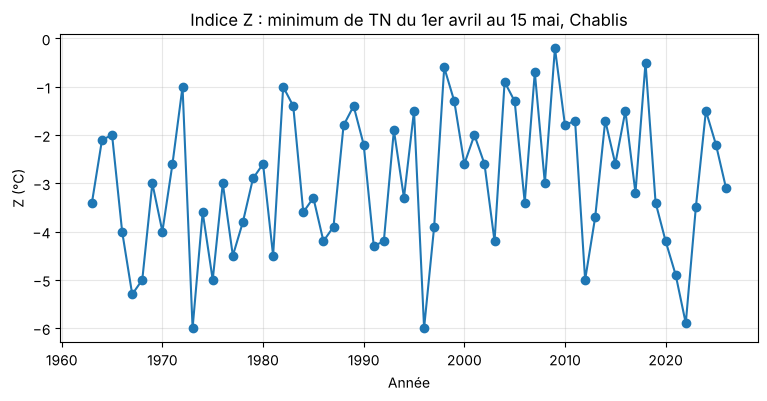

Z <= -1 °C : 59 années sur 64
Z <= -2 °C : 45 années sur 64
Z <= -3 °C : 34 années sur 64
Z <= -4 °C : 17 années sur 64
Z <= -5 °C : 7 années sur 64


In [5]:
tn_min_annuel = periode_tarification.groupby("annee")["TN"].min()
assert len(tn_min_annuel) == 64 and tn_min_annuel.notna().all()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tn_min_annuel.index, tn_min_annuel.values, marker="o")
ax.set_xlabel("Année"); ax.set_ylabel("Z (°C)")
ax.set_title("Indice Z : minimum de TN du 1er avril au 15 mai, Chablis")
ax.grid(alpha=0.3)
plt.show()

# Fréquence de passage sous quelques seuils
for z0 in [-1, -2, -3, -4, -5]:
    print(f"Z <= {z0} °C : {(tn_min_annuel <= z0).sum()} années sur {len(tn_min_annuel)}")

# Sauvegarde, utilisée par 02_tarification et 03_risque_de_base
tn_min_annuel.rename("Z").reset_index().to_csv(PROC / "indice_Z_chablis_1963_2026.csv", index=False)

**Limite connue : représentativité de la station.** La station de Chablis est à 141 m, en fond de vallée du Serein.
L'air froid s'accumule dans les points bas : la station enregistre probablement des minimales
plus basses que celles des coteaux, où se trouve une partie du vignoble. Cet effet augmente la fréquence de déclenchement
et le risque de paiement sans perte. Voir `04_annexe_stations.ipynb`.

## 4. Rendements viticoles

Les rendements de la coopérative ne sont pas publics. On utilise ceux des **AOP de l'Yonne** (2009–2025) comme approximation.
Justification : les appellations Chablis représentent environ 70 % de la surface AOP du département (calcul ci-dessous, 2017–2024),
et les deux séries de rendement évoluent ensemble sur les années communes.

Le taux de perte et sa comparaison avec l'indice sont traités dans `03_risque_de_base.ipynb`.

 annee  surface_aop_ha  recolte_aop_hl  rendement_aop_hl_ha
  2009          6699.0        394302.0                 58.9
  2010          6805.0        375413.0                 55.2
  2011          6910.0        418563.0                 60.6
  2012          7085.0        370865.8                 52.3
  2013          7205.5        290421.0                 40.3
  2014          7353.0        438114.4                 59.6
  2015          7505.2        448369.6                 59.7
  2016          7474.2        204837.8                 27.4
  2017          7636.6        343744.8                 45.0
  2018          7711.8        526760.8                 68.3
  2019          7836.0        353400.2                 45.1
  2020          8094.1        405878.7                 50.1
  2021          8139.5        231796.9                 28.5
  2022          8227.8        504997.9                 61.4
  2023          8359.3        561006.8                 67.1
  2024          8294.0        252962.0  

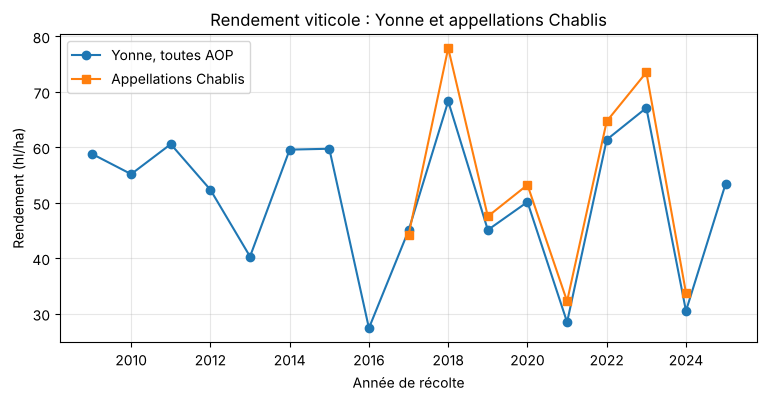

In [6]:
yonne = pd.read_csv(PROC / "douanes_yonne_aop_2009_2025.csv")
chablis_app = pd.read_csv(PROC / "douanes_chablis_appellations_2017_2024.csv")

print(yonne[["annee", "surface_aop_ha", "recolte_aop_hl", "rendement_aop_hl_ha"]].round(1).to_string(index=False))

# Part des appellations Chablis dans la surface AOP de l'Yonne
comp = chablis_app.merge(yonne, on="annee")
comp["part_chablis"] = comp["chablis_toutes_app_surface_ha"] / comp["surface_aop_ha"]
print("\nPart de la surface Chablis dans l'Yonne :")
print(comp[["annee", "part_chablis"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(yonne["annee"], yonne["rendement_aop_hl_ha"], marker="o", label="Yonne, toutes AOP")
ax.plot(chablis_app["annee"], chablis_app["chablis_toutes_app_rdt"], marker="s", label="Appellations Chablis")
ax.set_xlabel("Année de récolte"); ax.set_ylabel("Rendement (hl/ha)")
ax.set_title("Rendement viticole : Yonne et appellations Chablis")
ax.legend(); ax.grid(alpha=0.3)
plt.show()